In [213]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.metrics import RocCurveDisplay, precision_recall_curve, PrecisionRecallDisplay




# 1. Датасет

In [214]:
# Датасет из Аттестации. Исходные данные из БД логов о входах пользователей на компьютеры, обогащенные всевозможными признаками
df = pd.read_parquet("df_ml_final.parquet")
print(f"Размер датасета: {df.shape}")
print(f"Количество признаков: {len(df.columns)}")

Размер датасета: (3099, 67)
Количество признаков: 67


# 2. Целевая переменная

В качестве бинарной целевой переменной возьмем **is_high_risk**:
- 1 — событие с высоким уровнем опасности (rule_level > 10)
- 0 — событие с низким уровнем опасности (rule_level <= 10)
  
где rule_level - это предварительная оценка опасности события создаваемая сервером логов

In [215]:
df["is_high_risk"] = (df["rule_level"] > 10).astype(int)

target_col = "is_high_risk" # риск инцидента ИБ

print(f"Доля событий = 1: ({df[target_col].mean()*100:.1f}%)")

Доля событий = 1: (19.3%)


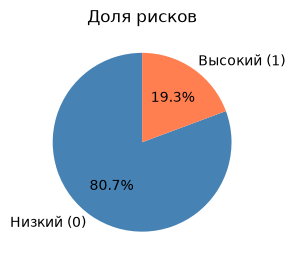

In [216]:
fig, ax = plt.subplots(figsize=(3, 3))

df[target_col].value_counts(normalize=True).plot(
    kind="pie", ax=ax,
    labels=["Низкий (0)", "Высокий (1)"],
    autopct="%1.1f%%",
    colors=["steelblue", "coral"],
    startangle=90
)
ax.set_title("Доля рисков")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Итого 19% целевой переменной равно 1. Баланс приемлимый. 

# 3. Выбор признаков

Можно чказать, что взяты они произвольно из множества признаков

In [217]:
print(df.columns.tolist())

['timestamp', 'logon_process', 'target_user', 'event_id', 'computer', 'rule_level', 'rule_id', 'is_server', 'date_day', 'wazuh_alert_count', 'is_domain_admin', 'is_anomaly', 'hour', 'day_of_week', 'is_business_hours', 'is_weekend', 'is_success', 'is_failure', 'user_events_day', 'user_computers_day', 'user_success_day', 'user_failure_day', 'server_events_day', 'server_users_day', 'server_success_day', 'server_failure_day', 'user_server_prev_count', 'is_first_time_pair', 'is_new_logon_type', 'is_new_logon_type_14d', 'user_logon_type_30d_count', 'user_logon_type_30d_rarity', 'logon_type_2', 'logon_type_4', 'logon_type_7', 'logon_type_8', 'logon_type_10', 'logon_type_11', 'iso_pred', 'iso_score', 'iso_anomaly', 'lof_pred', 'lof_score', 'lof_anomaly', 'ocsvm_pred', 'ocsvm_score', 'ocsvm_anomaly', 'iso_rank', 'lof_rank', 'ocsvm_rank', 'ensemble_score', 'ensemble_anomaly', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'user_events_day_log', 'user_success_day_log', 'user_failure_day_log', 'use

In [218]:
# Можно чказать, что взяты они произвольно из множества признаков
features_col = [
    "server_events_day",   
    "user_computers_day",                      
    "is_business_hours",     
    "is_first_time_pair",    
    "user_server_prev_count",
    "is_new_logon_type_14d"
]

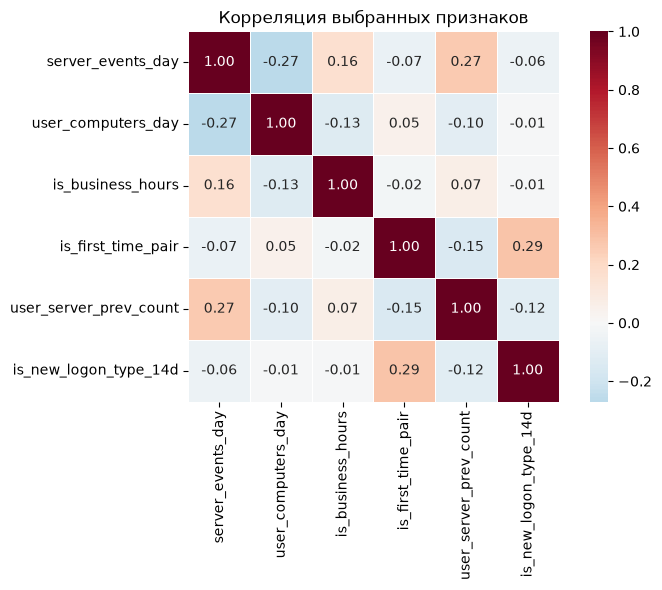

In [219]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[features_col].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5
)
plt.title("Корреляция выбранных признаков")
plt.tight_layout()
plt.show()

# смотрим чтобы не было сильных корреляций

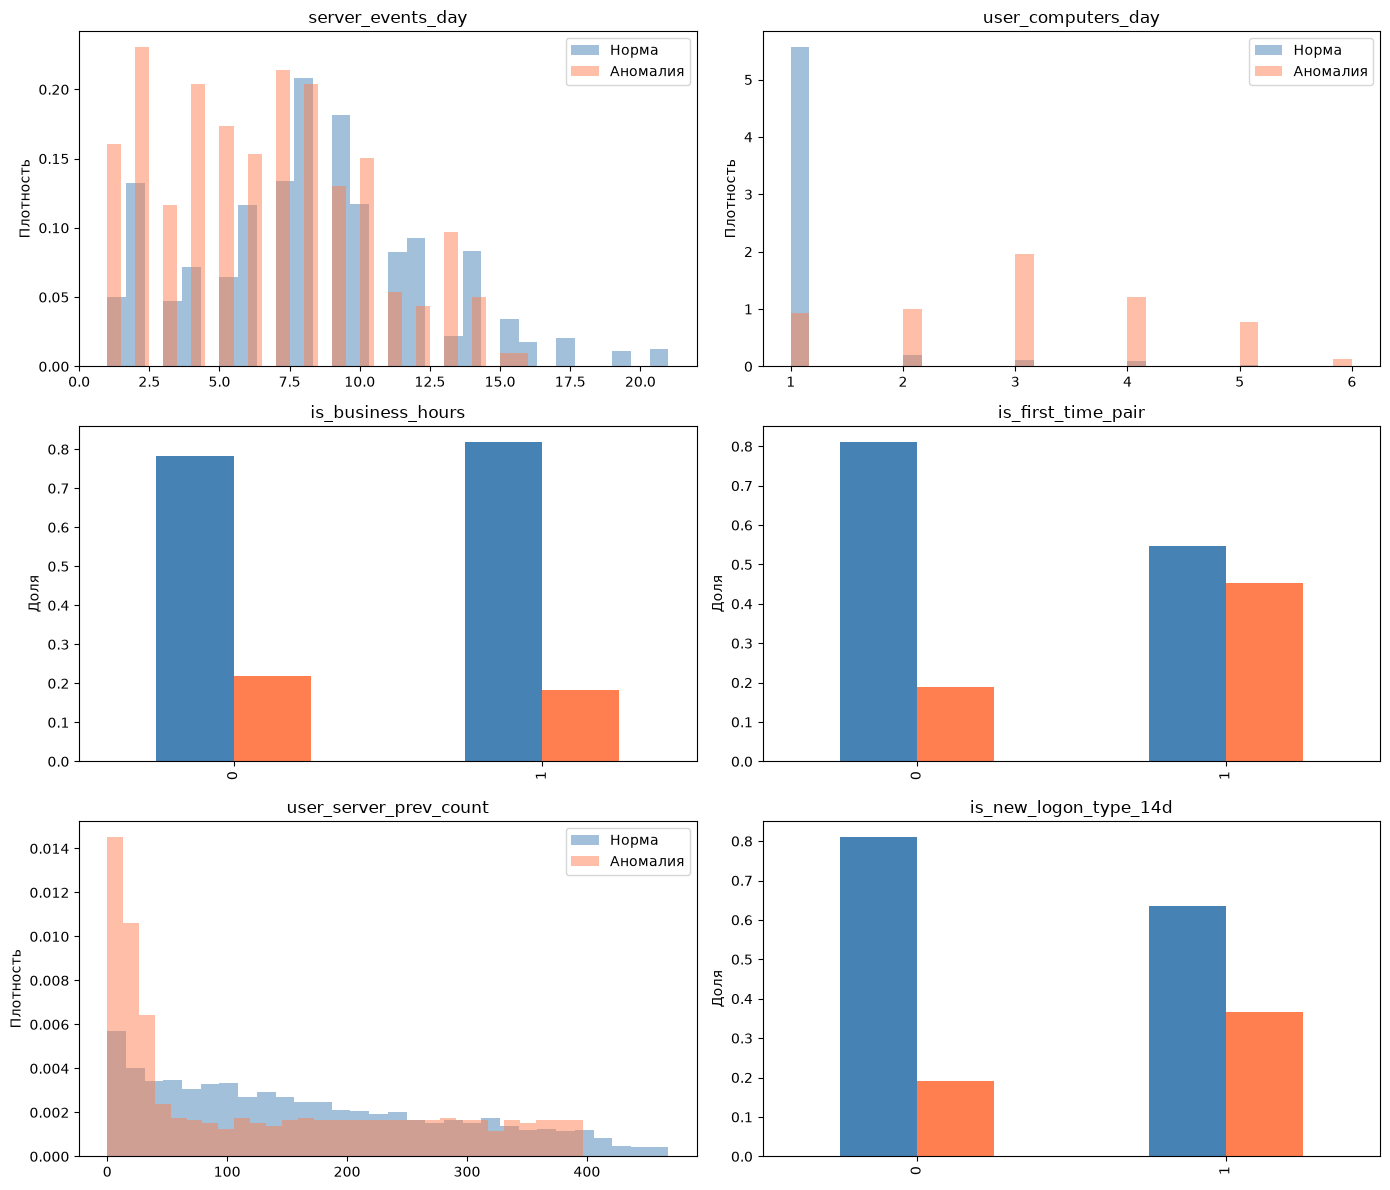

In [220]:
# смотрим как каждый признак связан с целевой переменной
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()  # превращаем 2D-массив в 1D для удобного перебора

for i, col in enumerate(features_col):
    if i < len(axes):
        # Если признак категориальный (мало уникальных значений <= 5)
        # используем столбцовую диаграмму с долями классов.
        if df[col].nunique() <= 5:

            ct = pd.crosstab(df[col], df[target_col], normalize="index")
            ct.plot(kind="bar", ax=axes[i], color=["steelblue", "coral"], legend=False)
            axes[i].set_title(f"{col}")
            axes[i].set_xlabel("")
            axes[i].set_ylabel("Доля")
        else:
            for cls, color, label in [(0, "steelblue", "Норма"), (1, "coral", "Аномалия")]:
                axes[i].hist(df[df[target_col]==cls][col], bins=30,
                            alpha=0.5, color=color, label=label, density=True)
            axes[i].set_title(f"{col}")
            axes[i].set_xlabel("")
            axes[i].set_ylabel("Плотность")
            axes[i].legend()

plt.tight_layout()
plt.show()

# 4. Обучение

In [221]:
# Разделение на обучающую и тестовую выборки

X = df[features_col]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)
print(f"Обучающая выборка: {X_train.shape}")
print(f"Тестовая выборка:   {X_test.shape}")
print(f"Доля аномалий в обучающей: {y_train.mean():.3f}")
print(f"Доля аномалий в тестовой:   {y_test.mean():.3f}")

Обучающая выборка: (2076, 6)
Тестовая выборка:   (1023, 6)
Доля аномалий в обучающей: 0.193
Доля аномалий в тестовой:   0.194


In [222]:
# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [223]:
# Обучение
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [224]:
# Степень и знак влияния параметров на целевую переменную
model.coef_

array([[ 0.0960072 ,  1.89677899,  0.17091981,  0.08282482, -0.19798861,
         0.21690305]])

In [225]:
for feature, coef in zip(features_col, model.coef_[0]):
    direction = "повышает риск" if coef > 0 else "снижает риск"
    strength = "сильно" if abs(coef) > 0.3 else "умеренно" if abs(coef) > 0.1 else "слабо"
    print(f"{feature:25s} {coef:+.4f}  →  {strength} {direction}")

server_events_day         +0.0960  →  слабо повышает риск
user_computers_day        +1.8968  →  сильно повышает риск
is_business_hours         +0.1709  →  умеренно повышает риск
is_first_time_pair        +0.0828  →  слабо повышает риск
user_server_prev_count    -0.1980  →  умеренно снижает риск
is_new_logon_type_14d     +0.2169  →  умеренно повышает риск


# 5. recall-precision, ROC

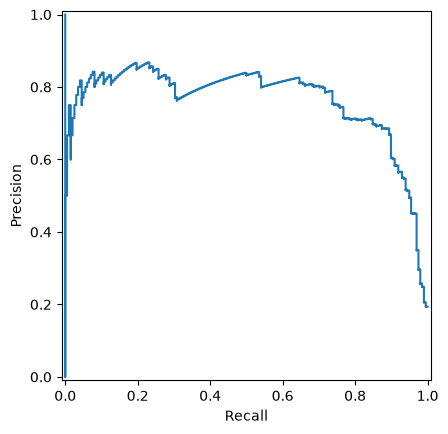

In [226]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

prec, recall, thresholds_pr = precision_recall_curve(y_test, y_prob, pos_label=1)

pr_display = PrecisionRecallDisplay(precision=prec, recall=recall).plot()


Высокая доля верных предсказаний

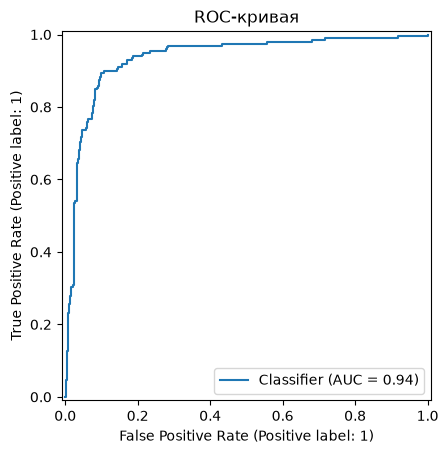

In [227]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC-кривая")
plt.show()

AUC = 0.94 подтверждает высокое качество модели